[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLO26 Instance Segmentation on a Custom Dataset

---

[![roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/train-yolo26-instance-segmentation-custom-data/) [![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

YOLO26 introduces a unified architecture designed to support detection, segmentation, and pose tasks within a single model family.

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [7]:
import os
from IPython.display import display, Image
HOME = os.getcwd()
print(HOME)

/content


### Install dependencies required for YOLO26

In [4]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow

import ultralytics

✅ Updated 'sync=False'
JSONDict("/root/.config/Ultralytics/settings.json"):
{
  "settings_version": "0.0.8",
  "datasets_dir": "/content/datasets",
  "weights_dir": "weights",
  "runs_dir": "runs",
  "uuid": "5a7e8147d51176dcc0b75ba8087ed3e23616e4d7989e6fd2a1bdbbc7ff57f8a7",
  "sync": false,
  "api_key": "",
  "openai_api_key": "",
  "clearml": true,
  "comet": true,
  "dvc": true,
  "mlflow": true,
  "raytune": true,
  "tensorboard": false,
  "wandb": false,
  "vscode_msg": true,
  "openvino_msg": true
}
💡 Learn more about Ultralytics Settings at https://docs.ultralytics.com/usage/settings


### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

In [25]:
!wget -q https://media.roboflow.com/notebooks/examples/dog.jpeg
!wget -q https://media.roboflow.com/notebooks/examples/dog-3.jpeg
!wget -q -O pose_image.jpg https://ultralytics.com/images/bus.jpg

## Inference with model pre-trained on COCO dataset

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m-seg summary (fused): 146 layers, 23,569,148 parameters, 0 gradients, 121.7 GFLOPs
Results saved to /content/runs/segment/predict-7
💡 Learn more at https://docs.ultralytics.com/modes/predict


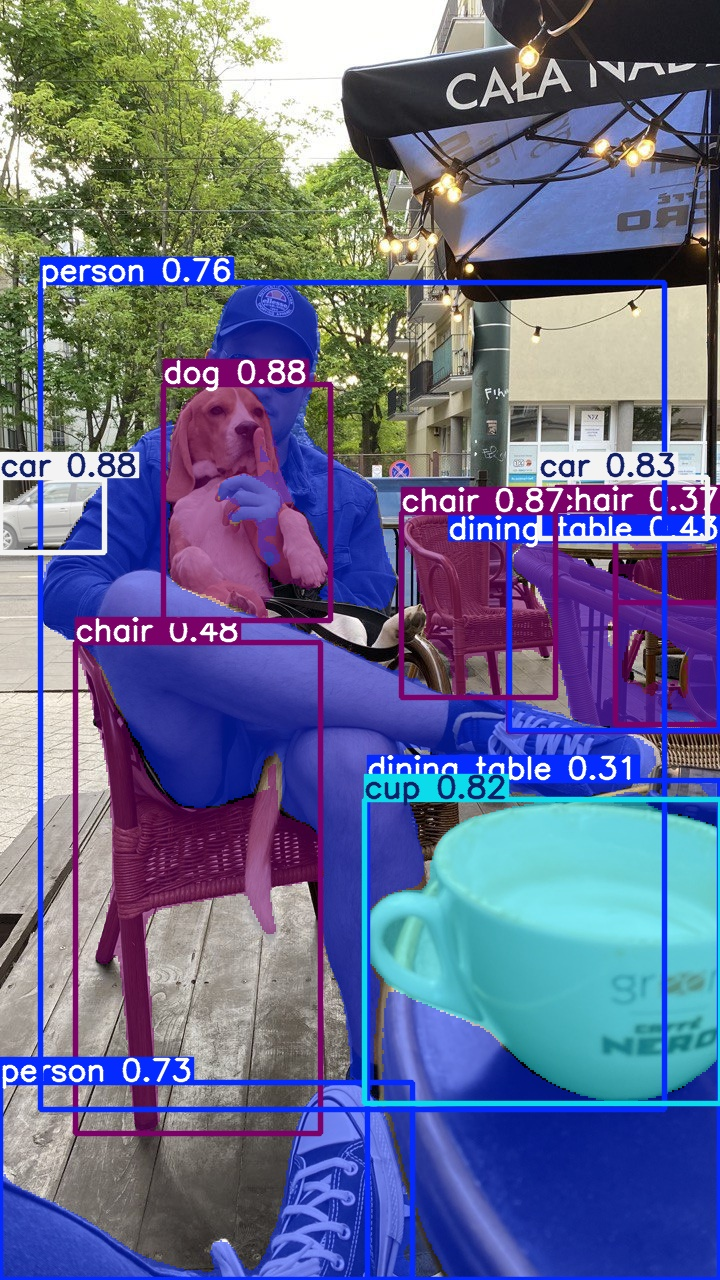

In [14]:
!yolo task=segment mode=predict model=yolo26m-seg.pt source={HOME}/dog-3.jpeg save=True verbose=False
display(Image(filename="/content/runs/segment/predict/dog-3.jpg"))

###  YOLO's Python interface

In [15]:
from ultralytics import YOLO
from PIL import Image
import requests

model = YOLO('yolo26m-seg.pt')
image = Image.open(f'{HOME}/dog-3.jpeg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

In [16]:
result.boxes.xyxy

tensor([[3.5324e-02, 4.7737e+02, 1.0489e+02, 5.5211e+02],
        [1.6317e+02, 3.8441e+02, 3.3052e+02, 6.2032e+02],
        [4.0188e+02, 5.1213e+02, 5.5512e+02, 6.9735e+02],
        [5.3972e+02, 4.7762e+02, 7.0746e+02, 5.3884e+02],
        [3.6477e+02, 7.9911e+02, 7.2000e+02, 1.1034e+03],
        [4.0150e+01, 2.8290e+02, 6.6416e+02, 1.1096e+03],
        [5.6543e-01, 1.0820e+03, 4.1216e+02, 1.2797e+03],
        [7.5298e+01, 6.4266e+02, 3.2095e+02, 1.1332e+03],
        [5.0993e+02, 5.4003e+02, 7.1979e+02, 7.3047e+02],
        [6.1912e+02, 5.1160e+02, 7.1939e+02, 5.3969e+02],
        [5.0821e+02, 5.3983e+02, 7.2000e+02, 7.3140e+02],
        [6.1518e+02, 5.1146e+02, 7.2000e+02, 7.2451e+02],
        [3.6788e+02, 7.8060e+02, 7.1928e+02, 1.2794e+03],
        [6.1587e+02, 5.1097e+02, 7.2000e+02, 6.0243e+02]], device='cuda:0')

In [17]:
result.boxes.conf

tensor([0.8834, 0.8758, 0.8743, 0.8269, 0.8234, 0.7605, 0.7330, 0.4836, 0.4300, 0.3719, 0.3587, 0.3232, 0.3108, 0.2548], device='cuda:0')

In [18]:
result.boxes.cls

tensor([ 2., 16., 56.,  2., 41.,  0.,  0., 56., 60., 56., 56., 56., 60., 56.], device='cuda:0')

In [20]:
# Number of detected objects
print(len(result.masks.data))

# First object's mask
first_mask = result.masks.data[0]


14
torch.Size([640, 384])


## Image Classification

Image classification predicts the main class of an entire image.



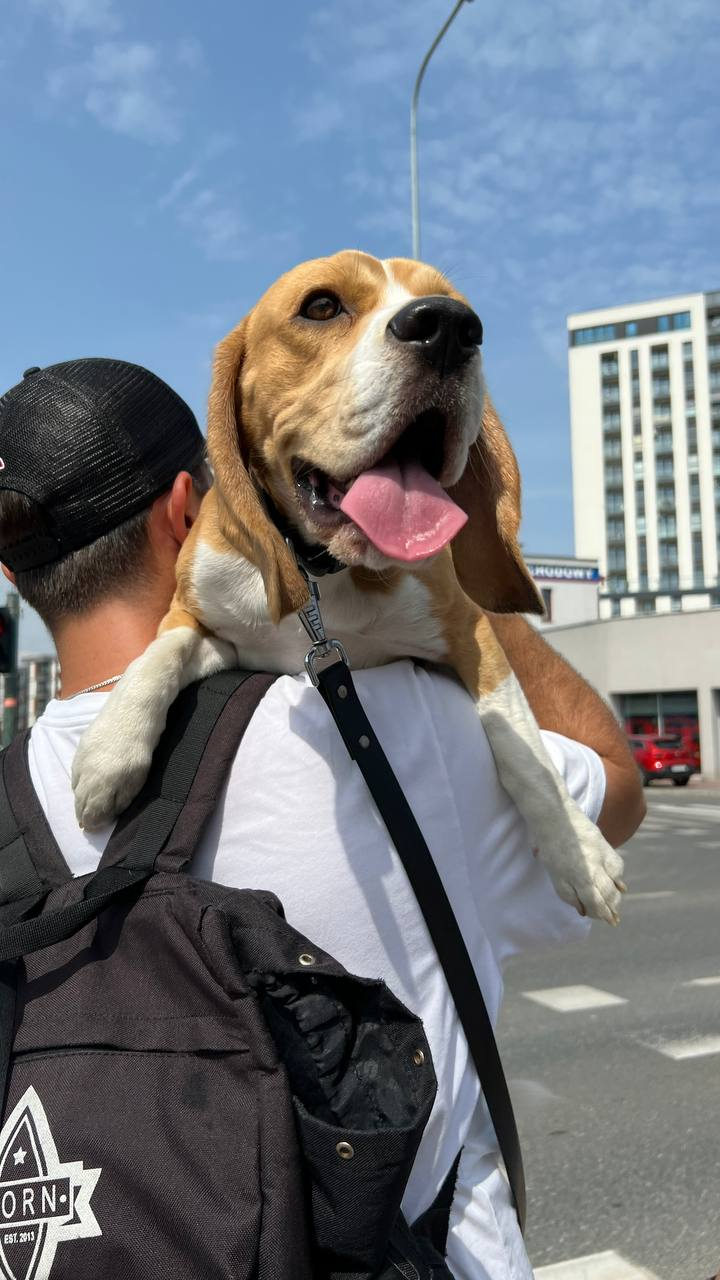

Top 5 predictions:
Walker_hound: 35.35%
beagle: 33.91%
English_foxhound: 7.44%
basset: 2.30%
bloodhound: 2.07%


In [24]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# Load a pre-trained classification model
classification_model = YOLO("yolo11n-cls.pt")

# Run classification
classification_result = classification_model.predict(
    source=f"{HOME}/dog.jpeg",
    verbose=False
)[0]

# Display the input image
display(Image.open(f"{HOME}/dog.jpeg"))

# Display top 5 predictions
print("Top 5 predictions:")

for class_id, confidence in zip(
    classification_result.probs.top5,
    classification_result.probs.top5conf
):
    class_name = classification_result.names[class_id]
    print(f"{class_name}: {float(confidence):.2%}")


### Pose Estimation

YOLO Pose Estimation detects people and identifies the locations of their body keypoints.

The output has the following shape:

`torch.Size([4, 17, 3])`

This represents:

- **4:** Number of detected people.
- **17:** Number of body keypoints for each person.
- **3:** Three values for each keypoint: X coordinate, Y coordinate, and confidence score.

#### The 17 COCO Body Keypoints

YOLO uses the COCO format, which defines 17 human body keypoints:

| Index | Keypoint |
|---|---|
| 0 | Nose |
| 1–4 | Eyes and ears |
| 5–6 | Shoulders |
| 7–8 | Elbows |
| 9–10 | Wrists |
| 11–12 | Hips |
| 13–14 | Knees |
| 15–16 | Ankles |

#### Understanding Individual Keypoints

Each keypoint is represented by three values:

`[X, Y, Confidence]`

- **X:** Horizontal position of the keypoint in the image.
- **Y:** Vertical position of the keypoint in the image.
- **Confidence:** Model confidence in the predicted keypoint location.

For example:

`[141.22, 445.24, 0.9928]`

This indicates a predicted keypoint at X = 141.22 and Y = 445.24, with approximately 99.28% confidence.



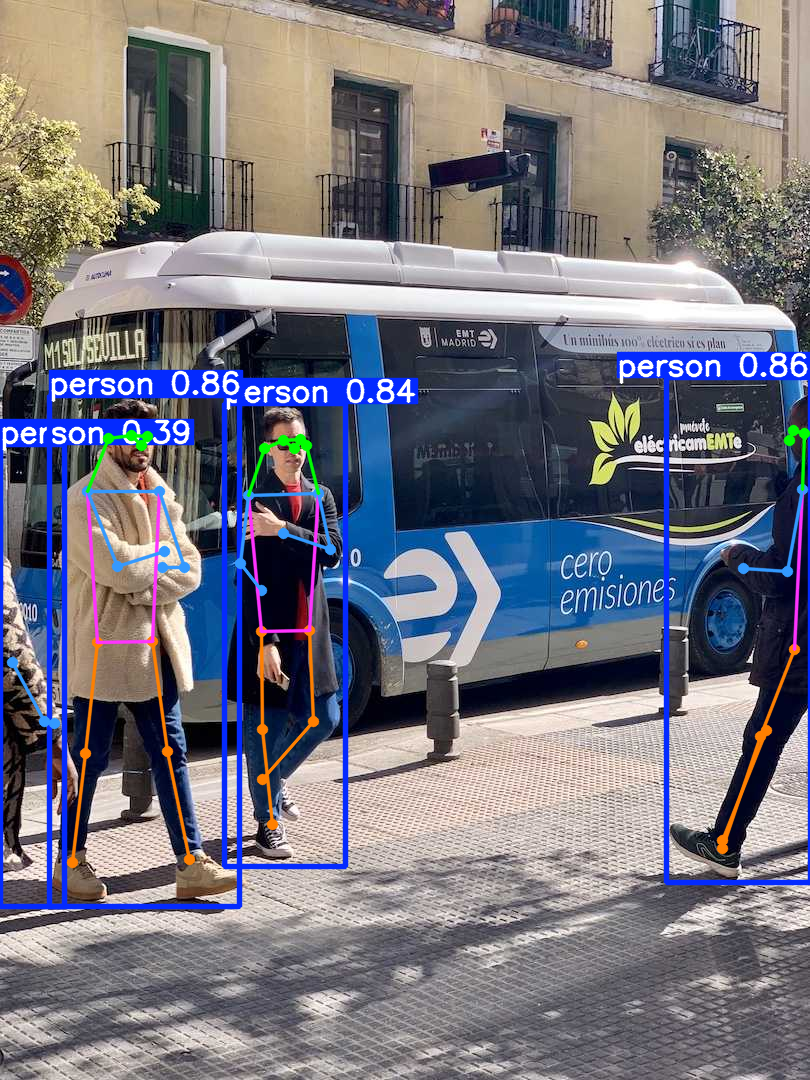

In [26]:
# Load pre-trained YOLO26 pose model
model = YOLO("yolo26n-pose.pt")

results = model.predict(
    source="pose_image.jpg",
    conf=0.25,
    device=0,
    verbose=False
)

# Display prediction
display(Image.fromarray(results[0].plot()[:, :, ::-1]))

In [27]:
result = results[0]

# Number of detected people
print("Detected people:", len(result.boxes))

# Keypoints information
print("Keypoints shape:", result.keypoints.data.shape)

# Display keypoints of the first person
if len(result.keypoints.data) > 0:
    print(result.keypoints.data[0])

Detected people: 4
Keypoints shape: torch.Size([4, 17, 3])
tensor([[1.4122e+02, 4.4524e+02, 9.9281e-01],
        [1.4796e+02, 4.3629e+02, 9.1388e-01],
        [1.3124e+02, 4.3578e+02, 9.9527e-01],
        [1.5161e+02, 4.3988e+02, 1.2709e-01],
        [1.0842e+02, 4.3858e+02, 9.7531e-01],
        [1.5946e+02, 4.9122e+02, 9.9488e-01],
        [8.7034e+01, 4.9194e+02, 9.9559e-01],
        [1.8453e+02, 5.6787e+02, 9.1040e-01],
        [1.1712e+02, 5.6662e+02, 9.5944e-01],
        [1.6214e+02, 5.6797e+02, 8.5439e-01],
        [1.6441e+02, 5.5176e+02, 9.3439e-01],
        [1.5263e+02, 6.4137e+02, 9.9687e-01],
        [9.7833e+01, 6.4291e+02, 9.9684e-01],
        [1.6784e+02, 7.5197e+02, 9.9476e-01],
        [8.5968e+01, 7.5348e+02, 9.9352e-01],
        [1.8935e+02, 8.5977e+02, 9.9582e-01],
        [7.2880e+01, 8.6250e+02, 9.9445e-01]], device='cuda:0')


## Fine-tune YOLO26 on custom dataset

**NOTE:** When training YOLO26, make sure your data is located in `datasets`. If you'd like to change the default location of the data you want to use for fine-tuning, you can do so through Ultralytics' `settings.json`. In this tutorial, we will use one of the [datasets](https://universe.roboflow.com/liangdianzhong/-qvdww) available on [Roboflow Universe](https://universe.roboflow.com/). When downloading, make sure to select the `yolov11` export format.

In [29]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = rf.workspace("roboflow-jvuqo")
project = workspace.project("car-part-detection-with-damage-part-ubaii")
version = project.version(4)
dataset = version.download("yolo26")

/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Car-Part-Detection-with-Damage-Part-4 in yolo26:: 100%|██████████| 2007/2007 [00:00<00:00, 4883.87it/s]


## Custom Training

In [30]:
%cd {HOME}

!yolo task=segment mode=train model=yolo26m-seg.pt data={dataset.location}/data.yaml epochs=30 imgsz=640 plots=True

/content
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/Car-Part-Detection-with-Damage-Part-4/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [ ]:
!ls {HOME}/runs/segment/train/

args.yaml			 MaskP_curve.png     train_batch881.jpg
BoxF1_curve.png			 MaskPR_curve.png    train_batch882.jpg
BoxP_curve.png			 MaskR_curve.png     val_batch0_labels.jpg
BoxPR_curve.png			 results.csv	     val_batch0_pred.jpg
BoxR_curve.png			 results.png	     val_batch1_labels.jpg
confusion_matrix_normalized.png  train_batch0.jpg    val_batch1_pred.jpg
confusion_matrix.png		 train_batch1.jpg    val_batch2_labels.jpg
labels.jpg			 train_batch2.jpg    val_batch2_pred.jpg
MaskF1_curve.png		 train_batch880.jpg  weights


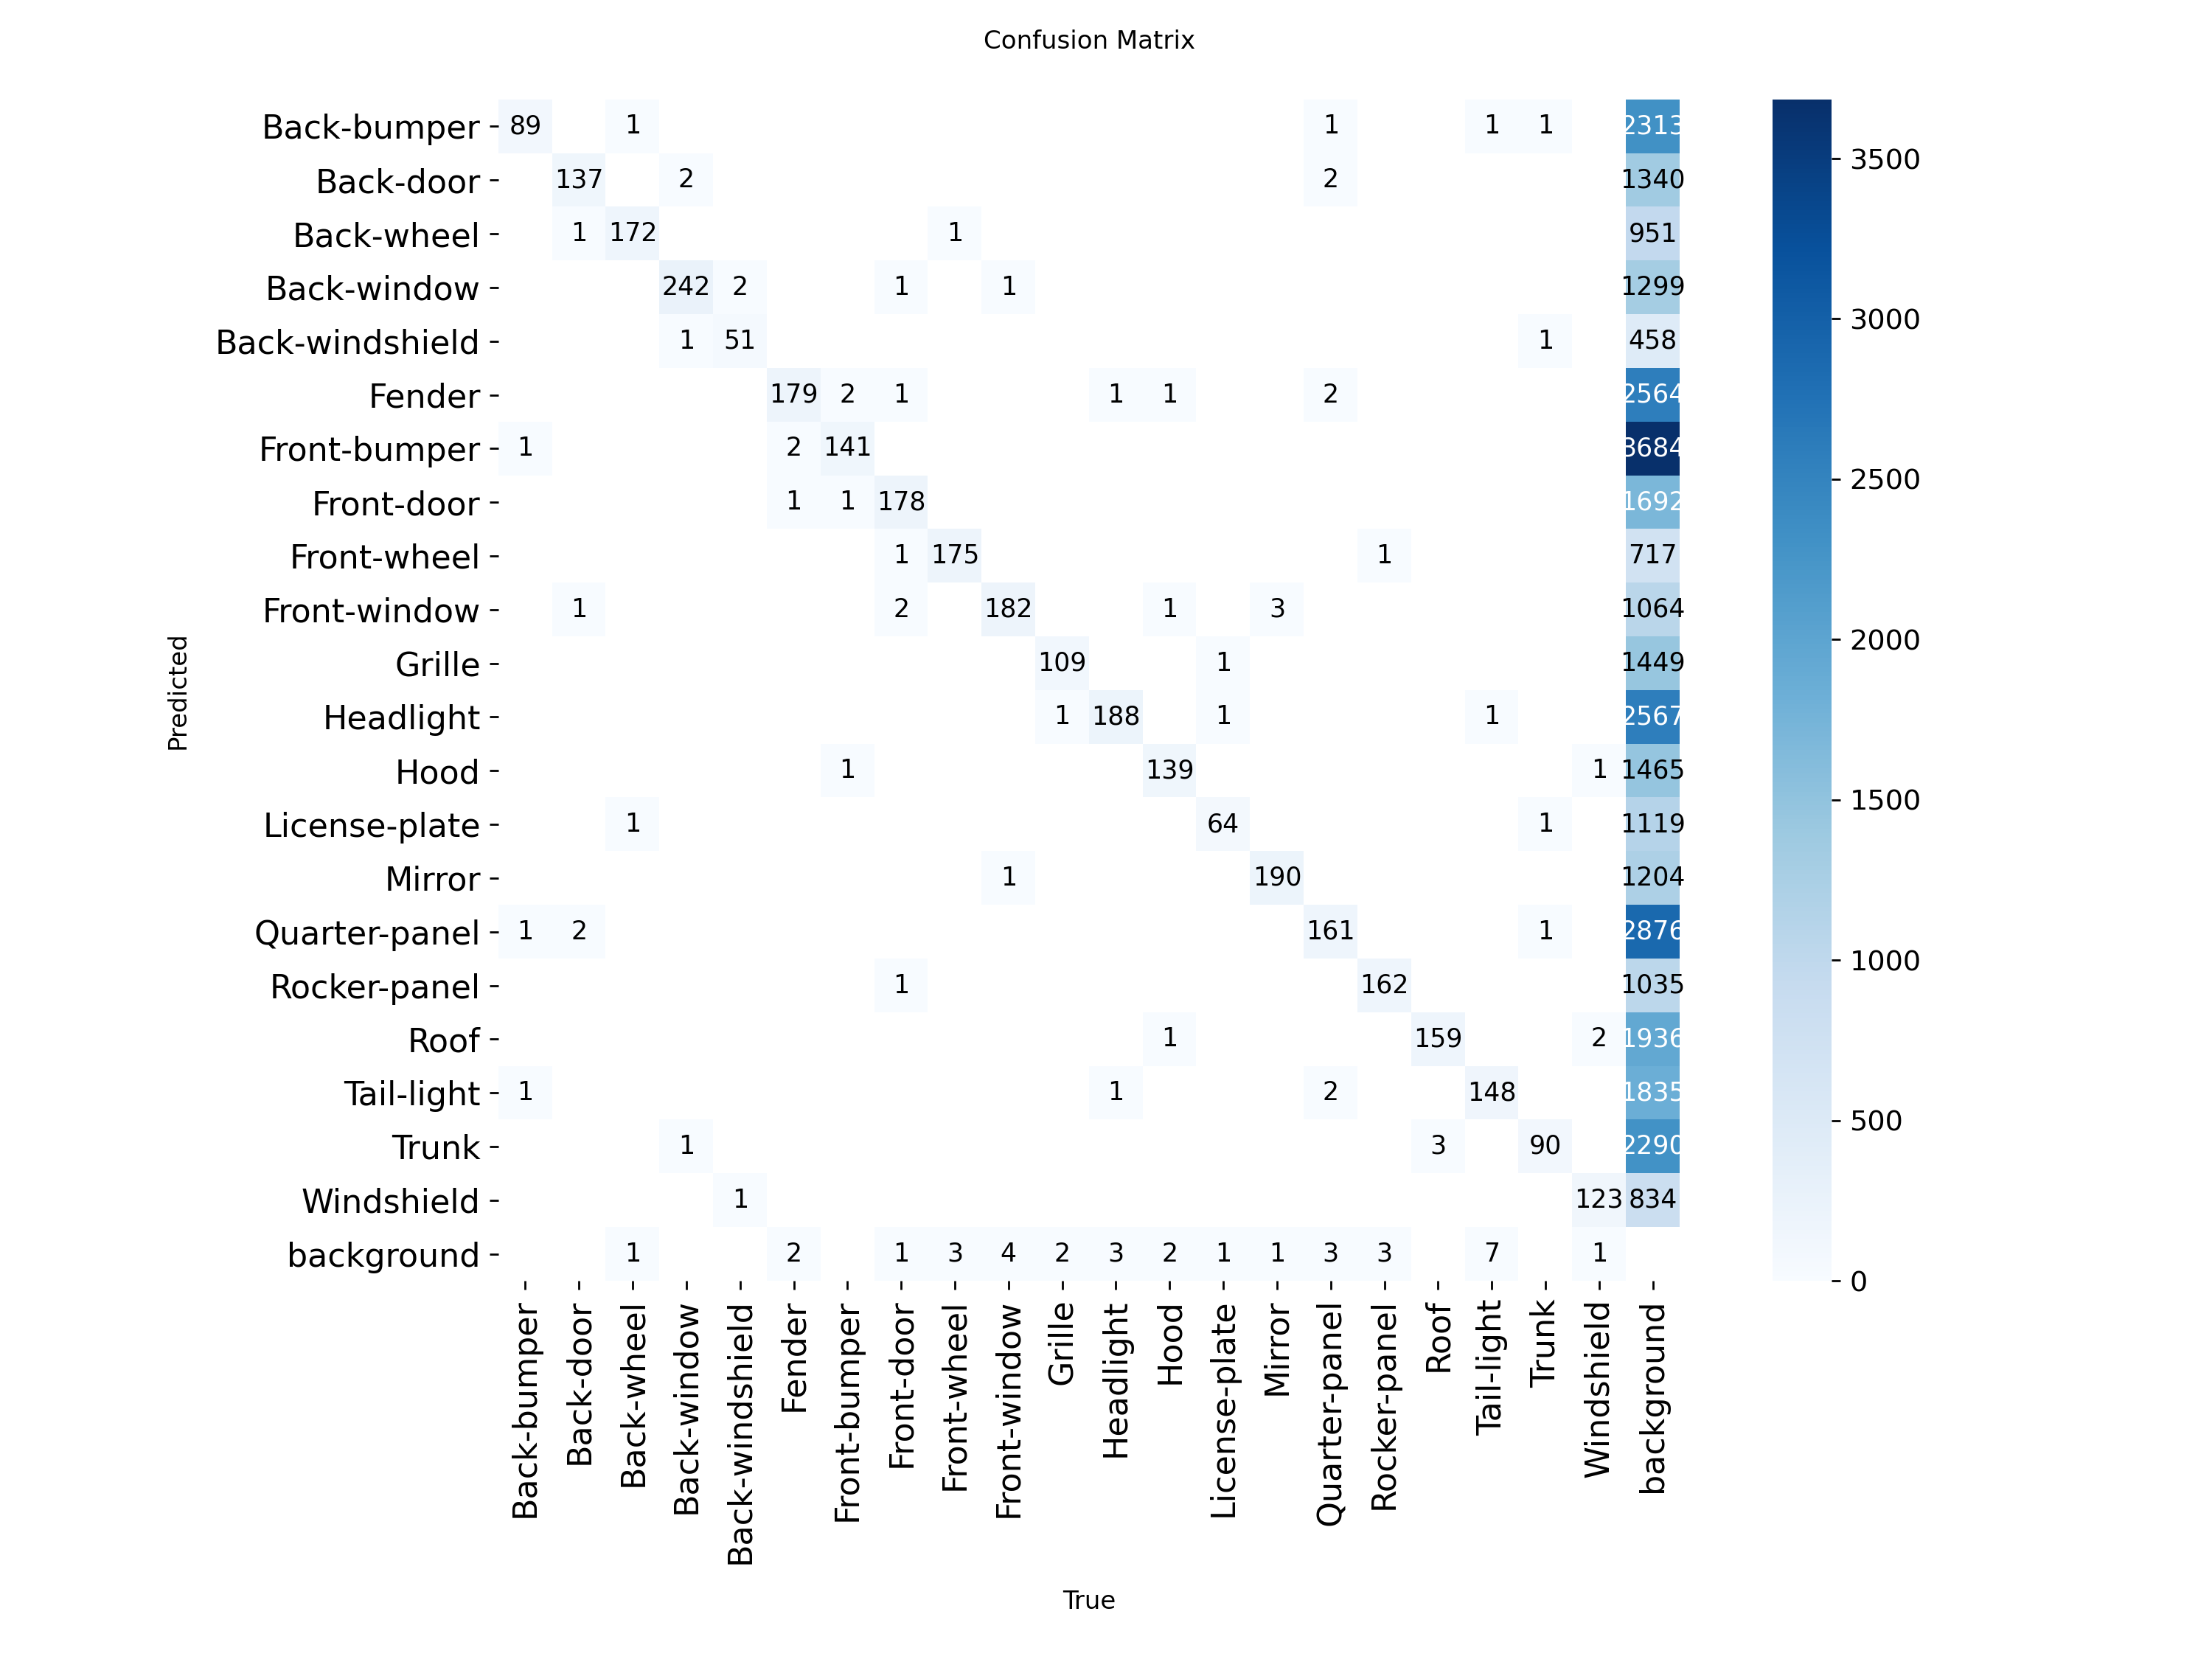

In [31]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

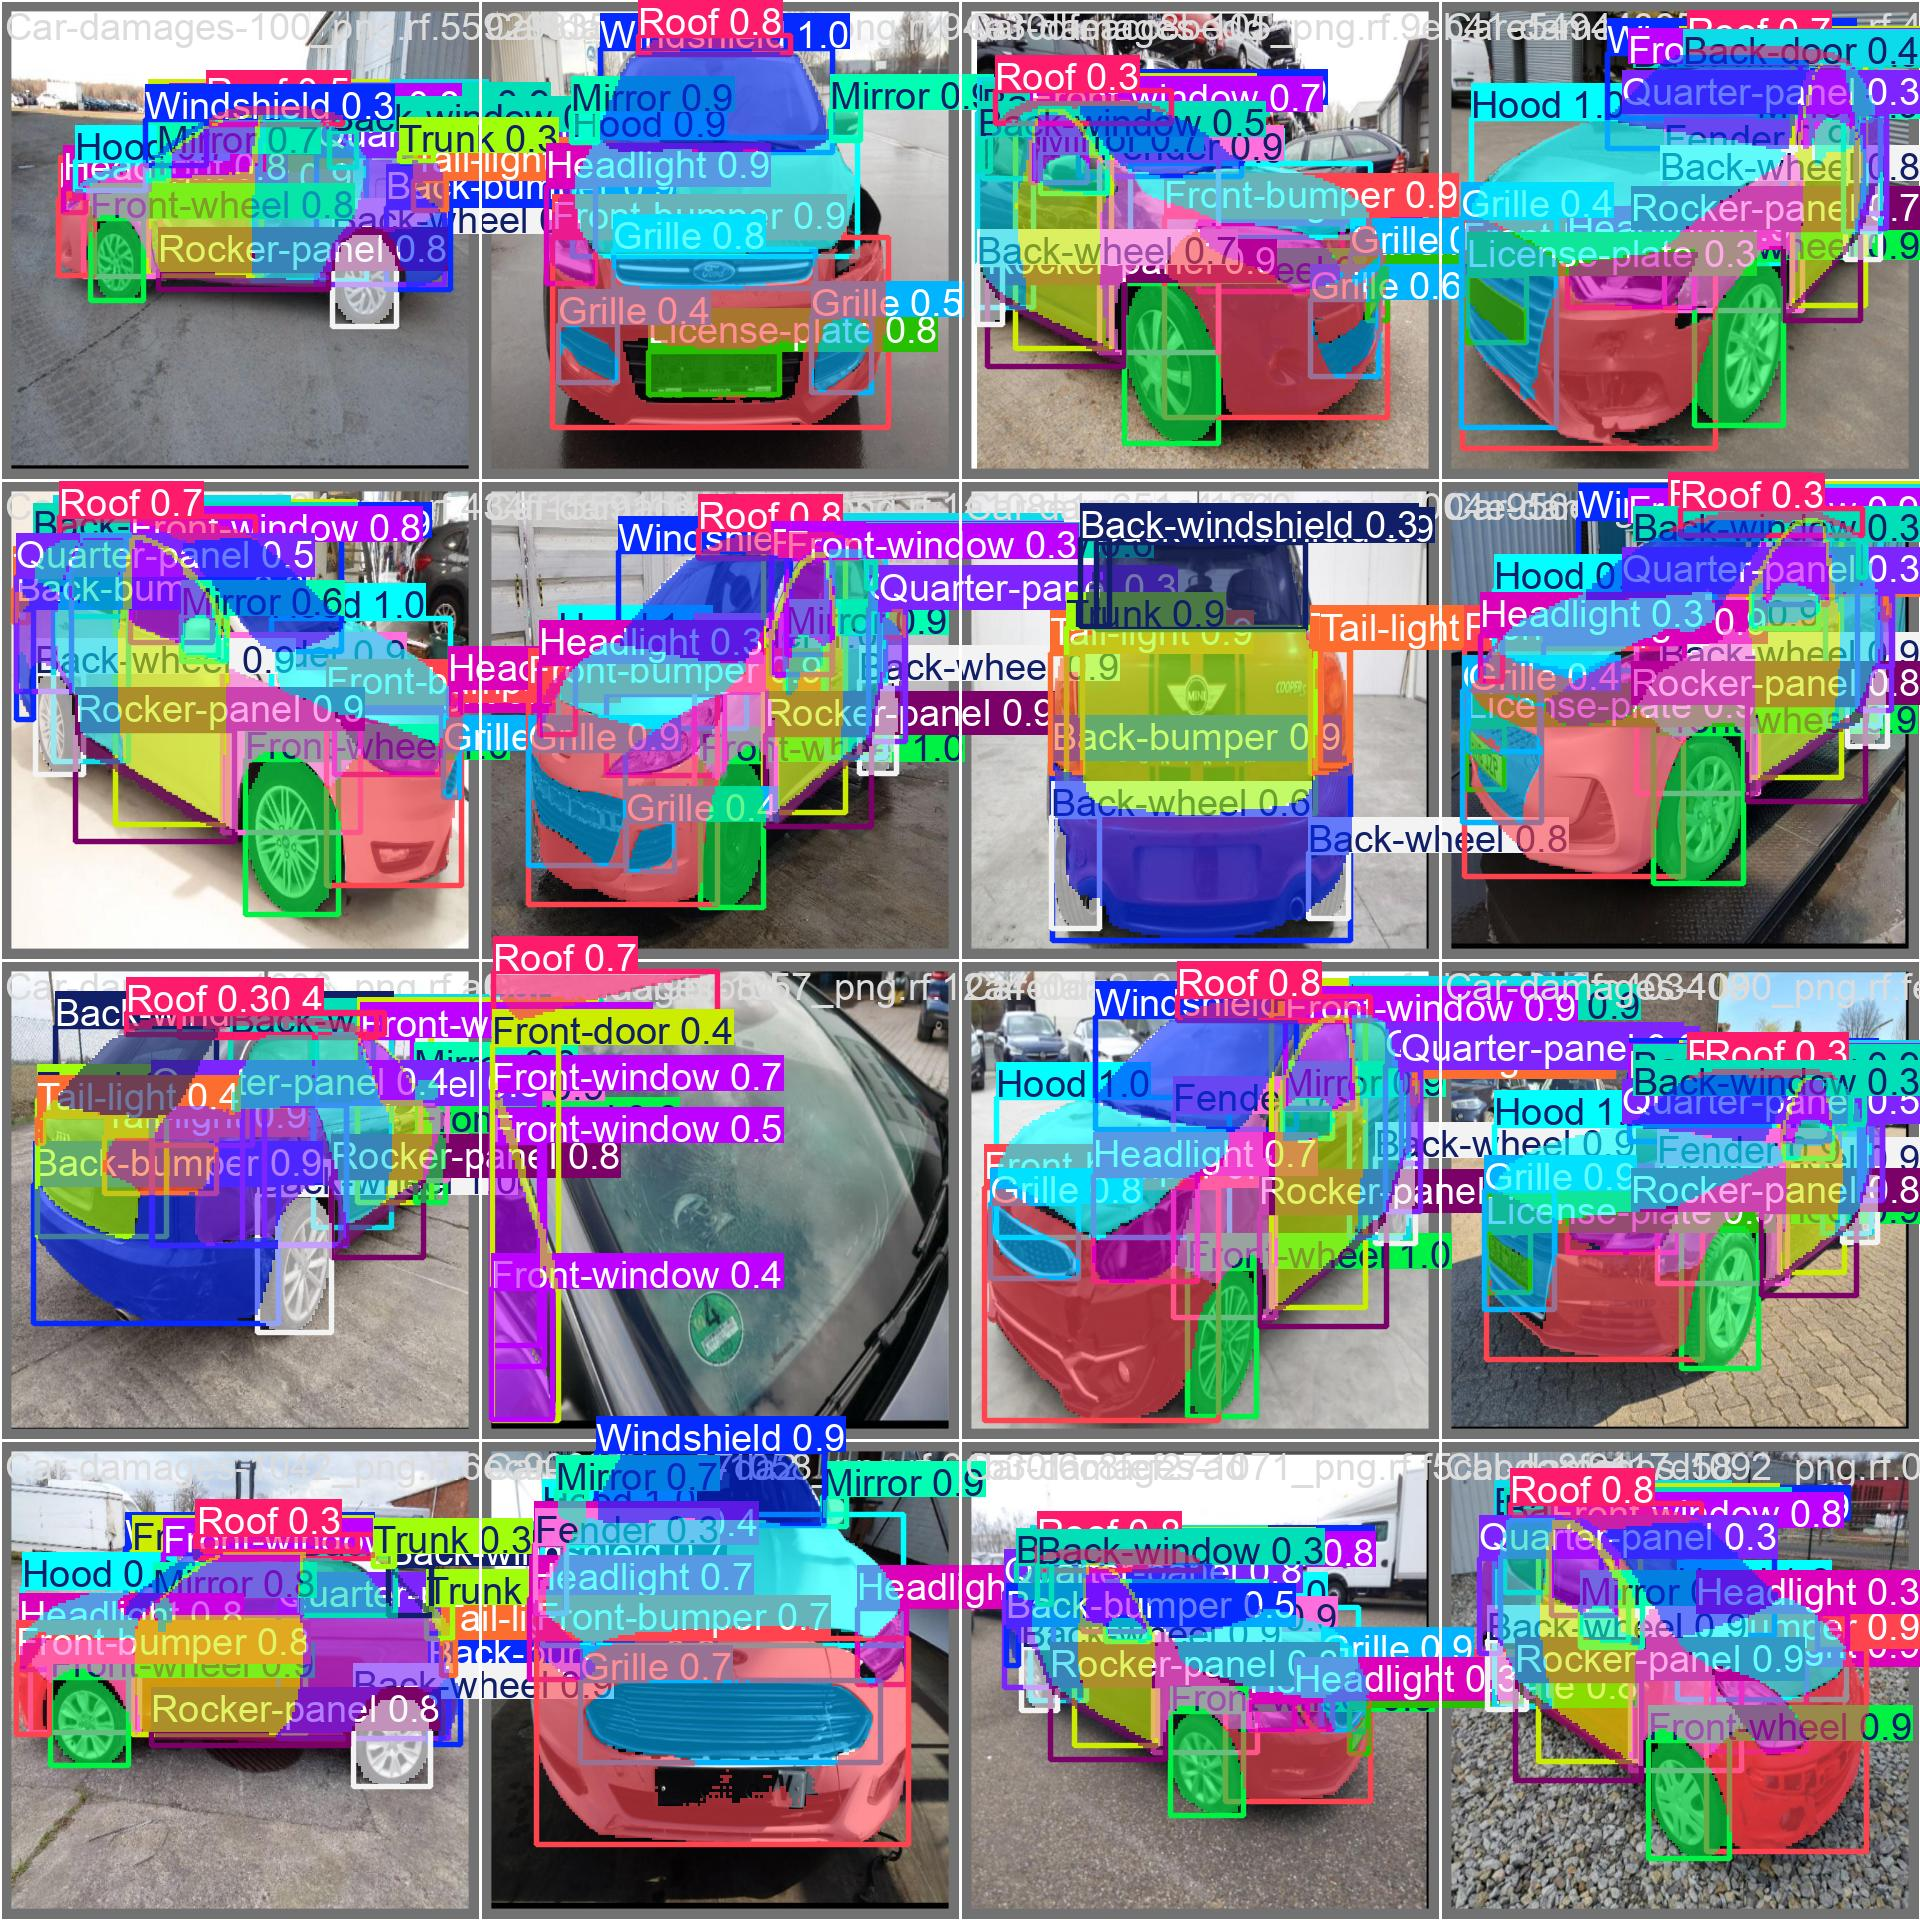

In [32]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/val_batch0_pred.jpg', width=600)

## Inference with custom model

### CLI

In [33]:
!yolo task=segment mode=predict model={HOME}/runs/segment/train/weights/best.pt source={dataset.location}/test/images save=True verbose=False


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m-seg summary (fused): 146 layers, 23,523,659 parameters, 0 gradients, 121.5 GFLOPs
Results saved to /content/runs/segment/predict-8
💡 Learn more at https://docs.ultralytics.com/modes/predict
